# Local Genealogies and Introgressed Segments

Near the red wing-pattern locus, the butterfly study found that nearby
positions can support different trees. Use twelve phased sequences from
the simulated founder population to see how recombination changes
genealogies and how haplotype matching recovers them. Then trace the
population paths in the ancient-DNA example and distinguish the three
dates in the *BRCA1* case.

In [1]:
library(hpgR)
options(repr.plot.width = 10, repr.plot.height = 4.5,
        repr.plot.pointsize = 14, warn = 1)
truth_color <- "#B33B32"
estimate_color <- "#265991"
drawFigure <- function(name, draw, width = 10, height = 4.5) {
    options(repr.plot.width = width, repr.plot.height = height)
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width,
            height = height, pointsize = 14, family = "Helvetica",
            useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) {
        par(bg = "white")
        draw()
    }
    invisible(NULL)
}

In [2]:
ancestry_truth <- readRDS("data/population_history/ancestry_truth.rds")
observed <- readRDS("data/population_history/observed.rds")

## Observe the final DNA

The simulation starts at size 100. It goes through 20 generations at size 20
and expands to 1,000 over the next 40 generations. The full sample contains
64 diploid people and eight 10,000-base chromosomes. Each chromosome has a
0.2-Morgan map and the mutation rate is 2.5 × 10⁻⁵ per base per generation.

Use the first six people on chromosome 1. H1–H12 identify their paired
haplotypes. The copying model uses sites that vary among the twelve copies.
The mutation clock uses the full sequence span, including invariant sites.

In [3]:
panel <- observed
calibration <- populationHistoryDesign()$design
chromosome_length <- 10000L
chromosome <- panel$haplotypes[1:12, seq_len(chromosome_length), drop = FALSE]
polymorphic <- colSums(chromosome) > 0 & colSums(chromosome) < nrow(chromosome)
linked_sample <- list(
    haplotypes = chromosome[, polymorphic, drop = FALSE],
    positions = which(polymorphic) - 1L,
    sequenceLength = chromosome_length
)
print(c(sampled_haplotypes = nrow(chromosome),
    variable_sites = sum(polymorphic), analyzed_bases = chromosome_length))

sampled_haplotypes     variable_sites     analyzed_bases 
                12                276              10000 


## Can one tree explain both sites?

At site A, copies 1 and 3 carry the derived allele. At site B, copies 1
and 2 carry the derived allele. Under infinite sites, the descendants of
the two mutations must be disjoint or nested on a single tree. These
carrier groups overlap without nesting, producing all four two-site
haplotypes. The sites require different trees under the model. Looking
backward from a breakpoint $b$, the segments $[0,b)$ and $[b,L)$ follow
their respective parents.

## Read two recorded trees

The forward simulation stores ancestry at fixed positions. At base
2,500, H1 groups with H10. At base 7,500, H1 groups with H2. The leaves
are the same twelve haplotypes in both trees.

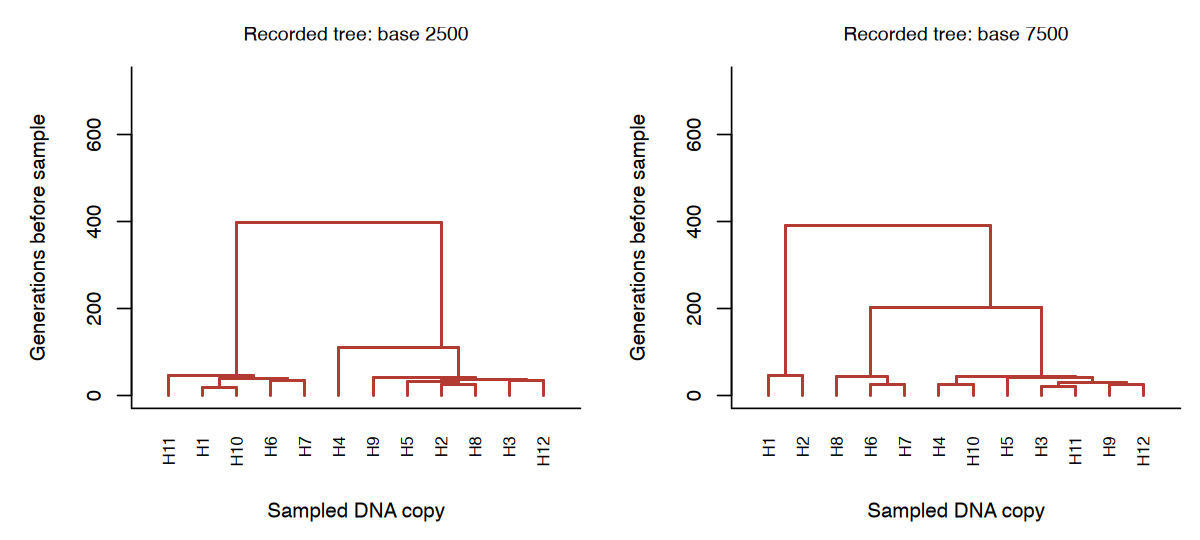

In [4]:
treePositions <- function(nodes) {
    samples <- nodes$node[nodes$is_sample]
    paths <- lapply(samples, function(node) {
        path <- node
        while (nodes$parent[match(node, nodes$node)] >= 0L) {
            node <- nodes$parent[match(node, nodes$node)]
            path <- c(path, node)
        }
        path
    })
    tipOrder <- integer()
    visit <- function(node) {
        if (node %in% samples) tipOrder <<- c(tipOrder, node)
        for (child in nodes$node[nodes$parent == node]) visit(child)
    }
    for (root in nodes$node[nodes$parent == -1L]) visit(root)
    vapply(nodes$node, function(node) {
        children <- tipOrder[vapply(tipOrder, function(sample)
            node %in% paths[[match(sample, samples)]], logical(1))]
        mean(range(match(children, tipOrder)))
    }, numeric(1))
}

drawTree <- function(nodes, title, color, ymax) {
    nodes$x <- treePositions(nodes)
    plot(NA, xlim = c(.4, 12.6), ylim = c(0, ymax), xaxt = "n",
         xlab = "Sampled DNA copy", ylab = "Generations before sample",
         main = title, cex.main = .95, bty = "l")
    for (i in which(nodes$parent >= 0)) {
        parent <- match(nodes$parent[i], nodes$node)
        segments(nodes$x[i], nodes$time[i], nodes$x[i], nodes$time[parent],
                 col = color, lwd = 1.8)
        segments(nodes$x[i], nodes$time[parent], nodes$x[parent],
                 nodes$time[parent], col = color, lwd = 1.8)
    }
    tips <- nodes$is_sample
    axis(1, nodes$x[tips], paste0("H", nodes$node[tips] + 1L),
         tick = FALSE, cex.axis = .8, las = 2, gap.axis = 0)
}
positions <- c(2500L,7500L)
truth_trees <- lapply(ancestry_truth$trees,function(t){
    parent <- setNames(t$edges$parent,t$edges$child)
    ids <- c(t$sample_nodes,setdiff(t$nodes$id,t$sample_nodes))
    p <- unname(parent[as.character(ids)])
    data.frame(node=seq_along(ids)-1L,parent=ifelse(is.na(p),-1L,match(p,ids)-1L),
        time=t$nodes$time[match(ids,t$nodes$id)],is_sample=ids %in% t$sample_nodes)
})
drawFigure("population_arg_trees",function(){
    par(mfrow=c(1,2),mar=c(4.7,4.7,2.4,.7))
    ymax<-max(unlist(lapply(truth_trees,function(t)t$time)))*1.07
    for(pos in positions)drawTree(truth_trees[[as.character(pos)]],
        paste("Recorded tree: base",pos),truth_color,ymax)
})


## Store trees as intervals
A tree sequence stores each node once. Each edge identifies a parent, a
child, and the interval over which they are connected. At one position,
read the local tree from the edges whose intervals contain that position.
If copy $c$ inherits $[a,b)$ from $u$ and $[b,d)$ from $v$, one edge
stores each interval. Read $c$'s parent at $b$ from the second edge.
This representation shares edges across adjacent trees
([Kelleher et al., 2016](https://doi.org/10.1371/journal.pcbi.1004842)).

## Infer the local genealogies

Shared derived variants identify candidate ancestors. The source ancestor
builder groups focal sites by their carrier patterns and derived frequencies,
then extends each ancestor using consensus among those carriers.

Match older ancestors first with the Li–Stephens copying HMM. Then match the
observed copies against the ancestral sequences. The hidden state is the
copied ancestor. The fitted copying paths
give parent–child edges over genomic intervals. Initial node times give an
ordering of ancestors. The matcher probabilities control copying and mismatch.

For example, a sample carrying `110 | 011` matches candidate `110 | 100`
on the left and `011 | 011` on the right. This copying path matches the
six alleles with one switch.

In [5]:
inferred <- inferAncestry(linked_sample$haplotypes, linked_sample$positions,
    linked_sample$sequenceLength, recombinationProbability = .01,
    mismatchProbability = .001)
reconstructed <- ancestryData(inferred)
stopifnot(identical(reconstructed$observed$haplotypes, linked_sample$haplotypes),
          identical(reconstructed$observed$positions, linked_sample$positions))
print(c(inferred_local_trees = reconstructed$nTrees,
        observed_alleles_reconstructed = length(linked_sample$haplotypes)))

          inferred_local_trees observed_alleles_reconstructed 
                            62                           3312 


## Check the fitted trees against recorded ancestry

Use the mutation rate and the full panel's diversity-based size to put
the inferred branches on the same time axis as the recorded branches.
[Simulate and Date Local Genealogies](P8149_Lecture_9_Ancestral_Graphs.ipynb)
gives the mutation model and age intervals.

In [6]:
mutation_rate <- calibration$mutation_rate
prior_size <- estimateDiversitySize(panel$haplotypes, mutation_rate,
    sequenceLength = panel$sequenceLength)$Ne
dated <- dateAncestry(inferred, mutationRate = mutation_rate,
    populationSize = prior_size, timepoints = 40L)
estimated <- ancestryData(dated)
stopifnot(all(is.finite(dated$nodes$time)),
          all(abs(rowSums(dated$dating$posterior) - 1) < 1e-8),
          identical(estimated$observed$haplotypes, linked_sample$haplotypes))

 position cladePrecision cladeRecall   pairMAE   rootMAE
      125      0.3333333         0.3  62.15125  32.51499
     2500      0.2857143         0.2  89.17248  65.48501
     5000      0.3750000         0.3  41.22187 127.48501
     7500      0.4285714         0.3 108.80156 142.33179
     9875      0.5714286         0.4  57.40081  70.51499


cladePrecision    cladeRecall        pairMAE        rootMAE 
     0.3988095      0.3000000     71.7495935     87.6663576 


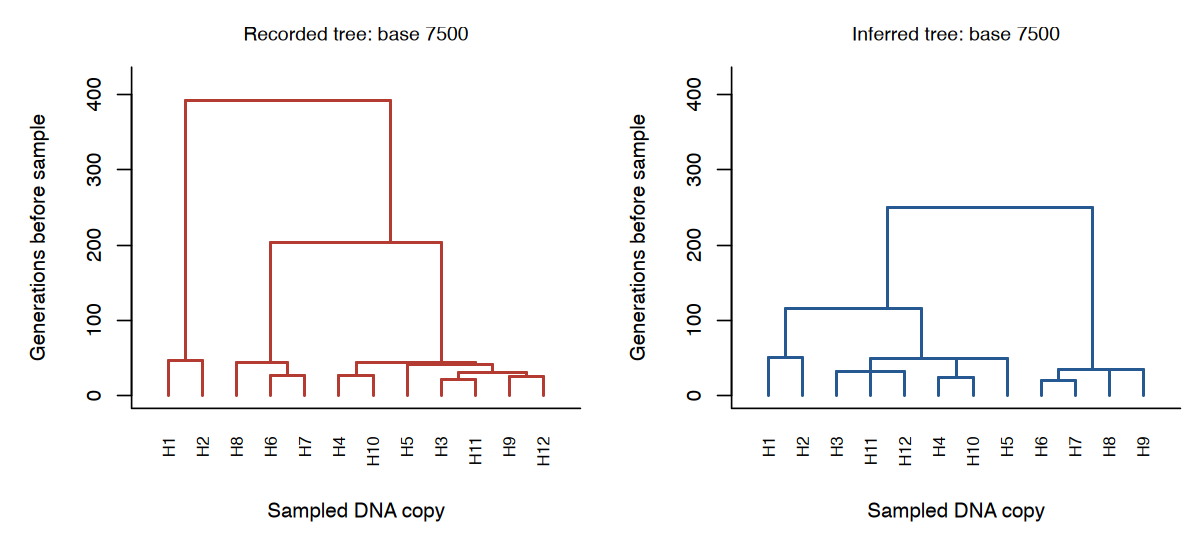

In [7]:
position <- 7500L
drawFigure("population_arg_inference",function(){
    par(mfrow=c(1,2),mar=c(4.7,4.7,2.4,.7))
    ymax<-max(truth_trees[[as.character(position)]]$time,estimated$intervals$tmrca)*1.07
    drawTree(truth_trees[[as.character(position)]],"Recorded tree: base 7500",truth_color,ymax)
    k<-findInterval(position-1,estimated$intervals$left)
    drawTree(estimated$localTrees[[k]],"Inferred tree: base 7500",estimate_color,ymax)
})
# Compare topology and dates at recorded positions, where ancestry was recorded.
validation <- do.call(rbind,lapply(c(125L,2500L,5000L,7500L,9875L),function(pos){
    t<-ancestry_truth$trees[[as.character(pos)]]
    truth_at <- structure(list(nodes=data.frame(id=t$nodes$id-1L,time=t$nodes$time,
        flags=as.integer(t$nodes$id %in% t$sample_nodes)),
        edges=data.frame(left=0,right=1,parent=t$edges$parent-1L,child=t$edges$child-1L),
        sampleIds=t$sample_nodes-1L,sequenceLength=1),class=c("hpgR_ancestry","list"))
    est_at<-dated
    take<-est_at$edges$left<=pos-1 & est_at$edges$right>pos-1
    est_at$edges<-est_at$edges[take,];est_at$edges$left<-0;est_at$edges$right<-1
    est_at$sequenceLength<-1
    data.frame(position=pos,t(compareAncestry(est_at,truth_at)$lengthWeighted))
}))
print(validation,row.names=FALSE)
print(colMeans(validation[,-1]))

## Interpret the comparison

Matching every input allele is a check of sequence reconstruction.
Clade precision gives the fraction of inferred clades found in the
recorded tree. Clade recall gives the fraction of recorded clades
recovered by the fit. Both exclude trivial clades consisting of one
sample or all samples. Across the five recorded positions, average
precision is about 0.40 and recall is about 0.30, as shown in the lecture.

## Trace a segment to its source

The simulated trees describe one breeding population. For ancient genomes, specify a history $H$ of sizes,
splits and migration. Under $H$ and recombination rate $r$, the graph
$\mathcal G$ includes the population of each lineage. Mutations at rate
$\mu$ generate the linked sequences $D$. The two rates are per base per generation.

$$
\Pr(\mathcal G\mid D,H,r,\mu)
\propto \Pr(D\mid\mathcal G,\mu)\Pr(\mathcal G\mid H,r).
$$

The earlier $f_4$ ratio estimated Neanderthal ancestry in living humans.
Here the target is early-human ancestry in Neanderthals. For one position,
count the fraction of posterior graphs in which a sampled
copy followed the specified migrant path. Hubisz et al. applied this to
both copies in each of two Neanderthals. At the 0.5 cutoff, light green and
dark green mark segments with one and two early-human copies, respectively.
Gray marks the deeper archaic source. The paper checks recovery in
simulations with known migrant segments and false calls in simulations
without migration.
[Hubisz et al. (2020), Figs. 5 and 7](https://doi.org/10.1371/journal.pgen.1008895).

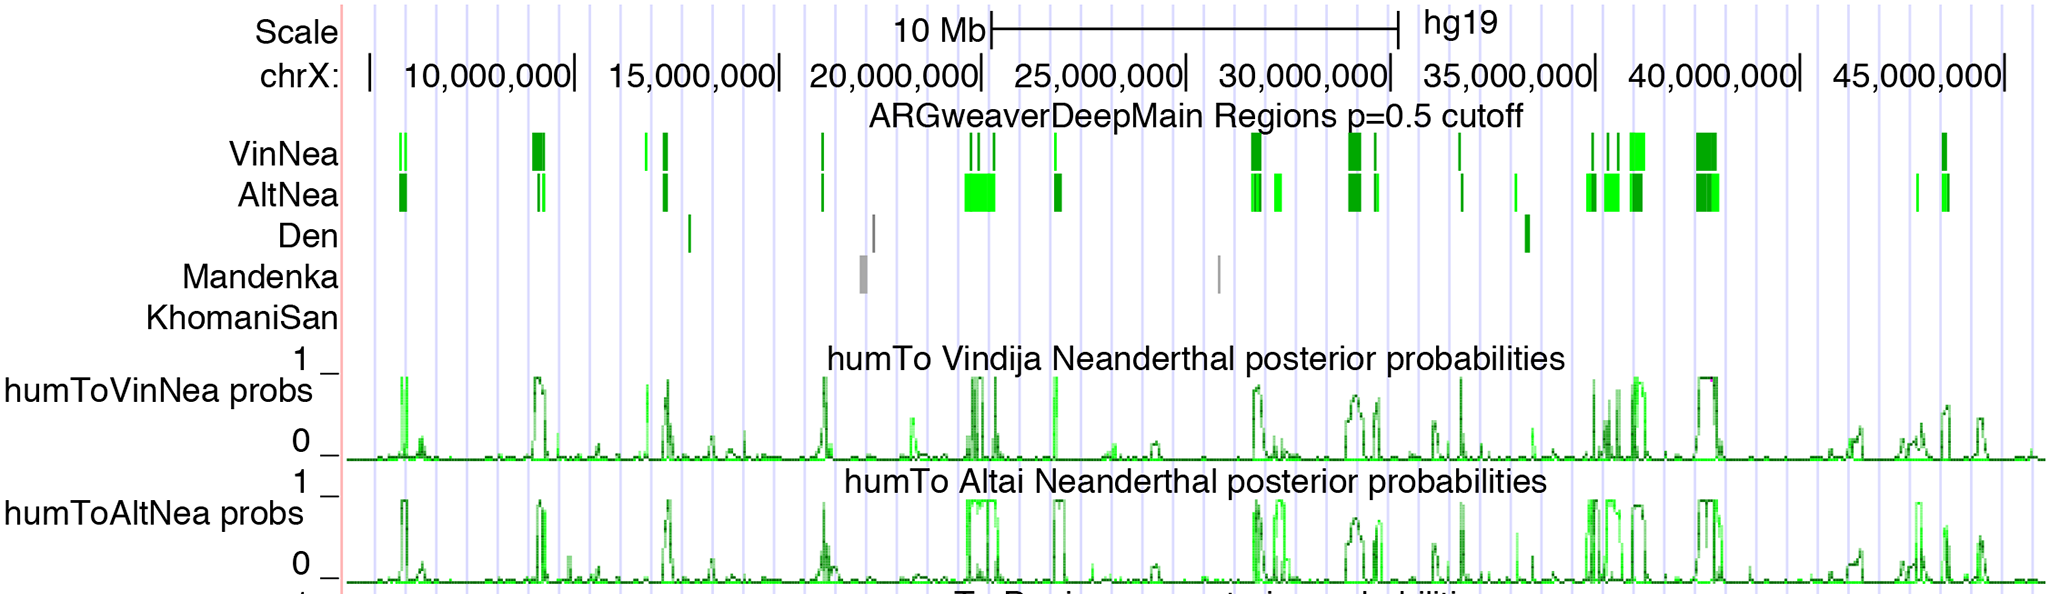

## A Denisovan-related source for Tibetan *EPAS1*

At *EPAS1*, the shared 32.7-kb haplotype and excess derived-allele sharing
support a Denisovan-related source in Tibetan highlanders. The study tested
ancestral sharing with no introgression as a competing explanation.
[Huerta-Sánchez et al. (2014), Fig. 2 and Extended Data Fig. 9](https://doi.org/10.1038/nature13408).

## Date a mutation and its arrival

Under a single origin, a mutation arose on the edge above the sampled
carriers' common ancestor. The child's age is a lower bound on mutation
age, and the parent's age is an upper bound.

Let \(c\) be the recombination fraction between a marker and the variant.
Along a lineage of \(g\) independent meioses, the number of recombinant
transmissions obeys \(J\mid g,c\sim\operatorname{Binomial}(g,c)\).
The probability of zero such transmissions is \((1-c)^g\), which falls
with \(g\). The published entry model compares haplotypes across populations
and also allows marker mutation. In the *BRCA1* example, shared
microsatellite alleles supported a single origin about 1,800 years ago
and later entry into the Ashkenazi Jewish gene pool about 400–500 years
ago. Both dates are model-based estimates
([Hamel et al., 2011](https://doi.org/10.1038/ejhg.2010.203)).

With a single introduction, the sampled recipient copies can coalesce at
the incoming chromosome or a later descendant. With multiple
introductions, their shared ancestor can lie in the source population.
The mutation date, entry date, and sample's carrier MRCA have different
interpretations.